# Stroke prediction replication and XAI extension

The paper-style model comparisons are retained. For the XAI extension, the split precedes BMI imputation, categorical encoding, correlation-based feature selection, and scaling; every learned preprocessing quantity is derived from training data only. Held-out metrics are descriptive and do not select the XAI model. A class-balanced logistic regression on the training-selected feature subset is pre-specified as the extension model to address severe outcome imbalance and provide a probabilistic baseline.

In [1]:
# Dependencies are installed from requirements-xai-lock.txt, not here.

In [2]:
# The versioned local Stroke CSV is used; no online fetch is required.

In [3]:
# XGBoost is provided by the reproducible project environment.

In [4]:
# imbalanced-learn is provided by the reproducible project environment.

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_curve, auc

from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from seaborn import heatmap
import seaborn as sns

import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

file_path = "../../data\\stroke\\healthcare-dataset-stroke-data.csv"

df_corr = pd.read_csv(file_path)

In [6]:
import sys
from pathlib import Path

FRAMEWORK_DIR = Path.cwd().parent / "xai_framework"

if str(FRAMEWORK_DIR) not in sys.path:
    sys.path.insert(0, str(FRAMEWORK_DIR))

from run_pipeline import run_pipeline

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


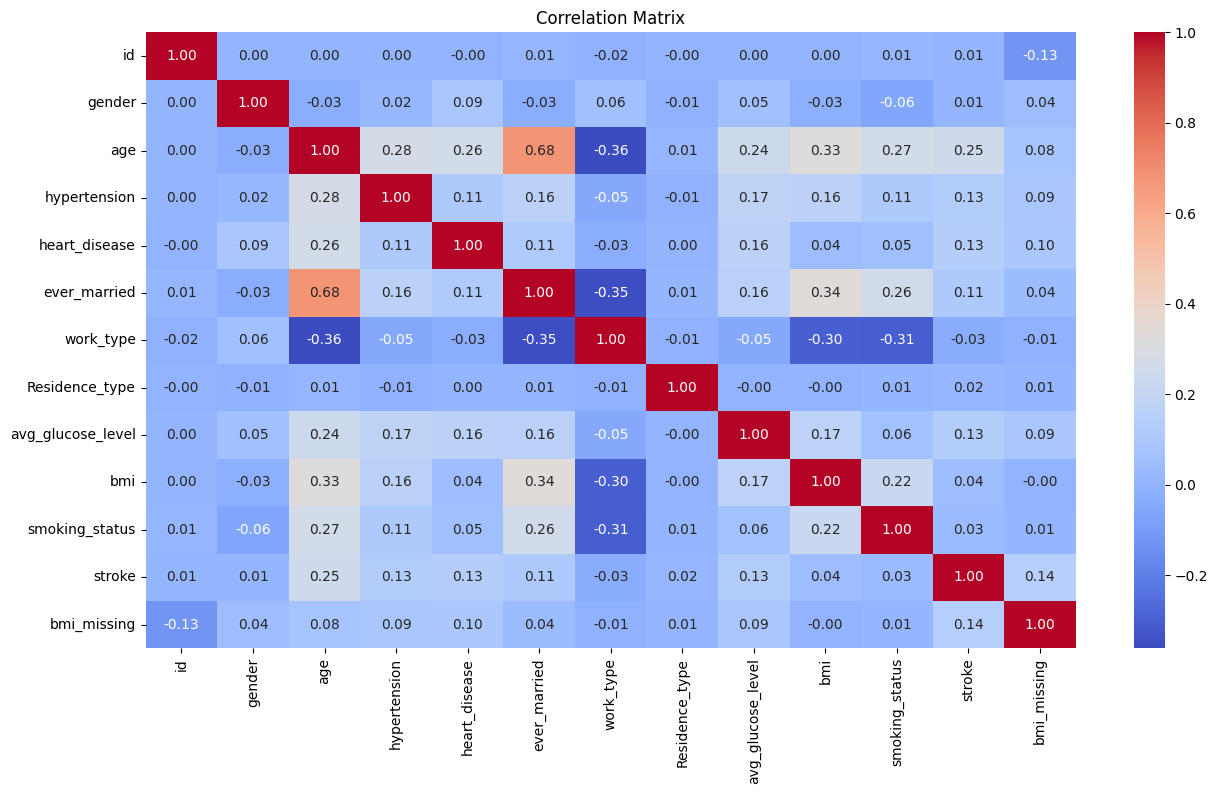

In [7]:
# remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other']

# creation of bmi_missing -> correct dataframe
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# fill BMI after flag
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# conversion categorical -> numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})

df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

# correlation matrix
corr_matrix = df_corr.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

In [8]:
df = pd.read_csv(file_path)
df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

y = df['stroke'].copy()
X_raw = df.drop(columns=['stroke', 'id']).copy()

# Split before imputation, encoding, feature selection, and scaling.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

for part in (X_train_raw, X_test_raw):
    part['bmi_missing'] = part['bmi'].isna().astype(int)

train_bmi_mean = X_train_raw['bmi'].mean()
X_train_raw['bmi'] = X_train_raw['bmi'].fillna(train_bmi_mean)
X_test_raw['bmi'] = X_test_raw['bmi'].fillna(train_bmi_mean)

categorical_cols = [
    'gender', 'smoking_status', 'Residence_type',
    'work_type', 'ever_married'
]
X_train_encoded = pd.get_dummies(
    X_train_raw, columns=categorical_cols, drop_first=False
)
X_test_encoded = pd.get_dummies(
    X_test_raw, columns=categorical_cols, drop_first=False
).reindex(columns=X_train_encoded.columns, fill_value=0)

# Learn the correlation-based feature set from training data only.
training_for_selection = X_train_encoded.copy()
training_for_selection['stroke'] = y_train.to_numpy()
training_correlations = training_for_selection.corr(numeric_only=True)['stroke'].abs()
selected_features = training_correlations[
    (training_correlations > 0.1)
    & (training_correlations.index != 'stroke')
].index.tolist()

X_train_full = X_train_encoded
X_test_full = X_test_encoded
X_train_sel = X_train_encoded[selected_features]
X_test_sel = X_test_encoded[selected_features]

In [9]:
print('Training rows:', len(X_train_full))
print('Test rows:', len(X_test_full))
print('Full features:', X_train_full.shape[1])
print('Training-selected features:', selected_features)

Training rows: 4087
Test rows: 1022
Full features: 21
Training-selected features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes']


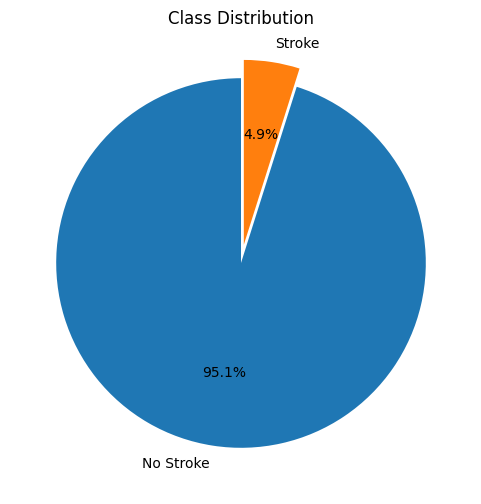

In [10]:
counts = y.value_counts()

labels = ['No Stroke', 'Stroke']
sizes = counts.values

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Class Distribution")
plt.show()

In [11]:
scaler_full = StandardScaler()
X_train_full = pd.DataFrame(
    scaler_full.fit_transform(X_train_full),
    columns=X_train_encoded.columns, index=X_train_encoded.index
)
X_test_full = pd.DataFrame(
    scaler_full.transform(X_test_full),
    columns=X_train_encoded.columns, index=X_test_encoded.index
)

scaler_sel = StandardScaler()
X_train_sel = pd.DataFrame(
    scaler_sel.fit_transform(X_train_sel),
    columns=selected_features, index=X_train_encoded.index
)
X_test_sel = pd.DataFrame(
    scaler_sel.transform(X_test_sel),
    columns=selected_features, index=X_test_encoded.index
)

In [12]:

def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc

In [13]:
def run_models(X_train, X_test, y_train, y_test):
    from imblearn.over_sampling import SMOTE

    # SMOTE (only on training set)
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    results = {}

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:,1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    # Decision Tree
    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:,1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    # Random Forest
    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:,1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    # SVM
    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:,1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    # KNN
    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:,1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    # XGBoost 
    try:
        xgb = XGBClassifier(eval_metric='logloss')
        xgb.fit(X_train, y_train)
        y_pred = xgb.predict(X_test)
        y_scores = xgb.predict_proba(X_test)[:,1]
        results["XGBoost"] = evaluate(y_test, y_pred, y_scores)
    except:
        print("XGBoost not installed")

    return results

In [14]:
results_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

In [15]:
def run_dnn(X_train, X_test, y_train, y_test):
    # SMOTE
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    return evaluate(y_test, y_pred, y_scores)

In [16]:
results_before["DNN"] = run_dnn(X_train_full, X_test_full, y_train, y_test)
results_after["DNN"] = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [17]:
def plot_results(results, title):
    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    model_colors = {
        "Logistic Regression": "#4c4a86",  # blue
        "SVM": "#6783c1",                  # orange
        "KNN": "#dbe4f0",                  # green
        "Decision Tree": "#e5a39b",        # red
        "Random Forest": "#514c88",        # purple
        "XGBoost": "#6e89c9"               # brown
    }

    colors = [model_colors[m] for m in plot_models]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    axs[0, 0].bar(plot_models, aucs, color=colors)
    axs[0, 0].set_title("AUC Comparison")
    axs[0, 0].set_ylabel("AUC")

    axs[0, 1].bar(plot_models, acc, color=colors)
    axs[0, 1].set_title("Accuracy Comparison")
    axs[0, 1].set_ylabel("Accuracy")

    axs[1, 0].bar(plot_models, f1, color=colors)
    axs[1, 0].set_title("F1 Comparison")
    axs[1, 0].set_ylabel("F1")

    axs[1, 1].bar(plot_models, recall, color=colors)
    axs[1, 1].set_title("Recall Comparison")
    axs[1, 1].set_ylabel("Recall")

    for ax in axs.flat:
        ax.tick_params(axis='x', rotation=45)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

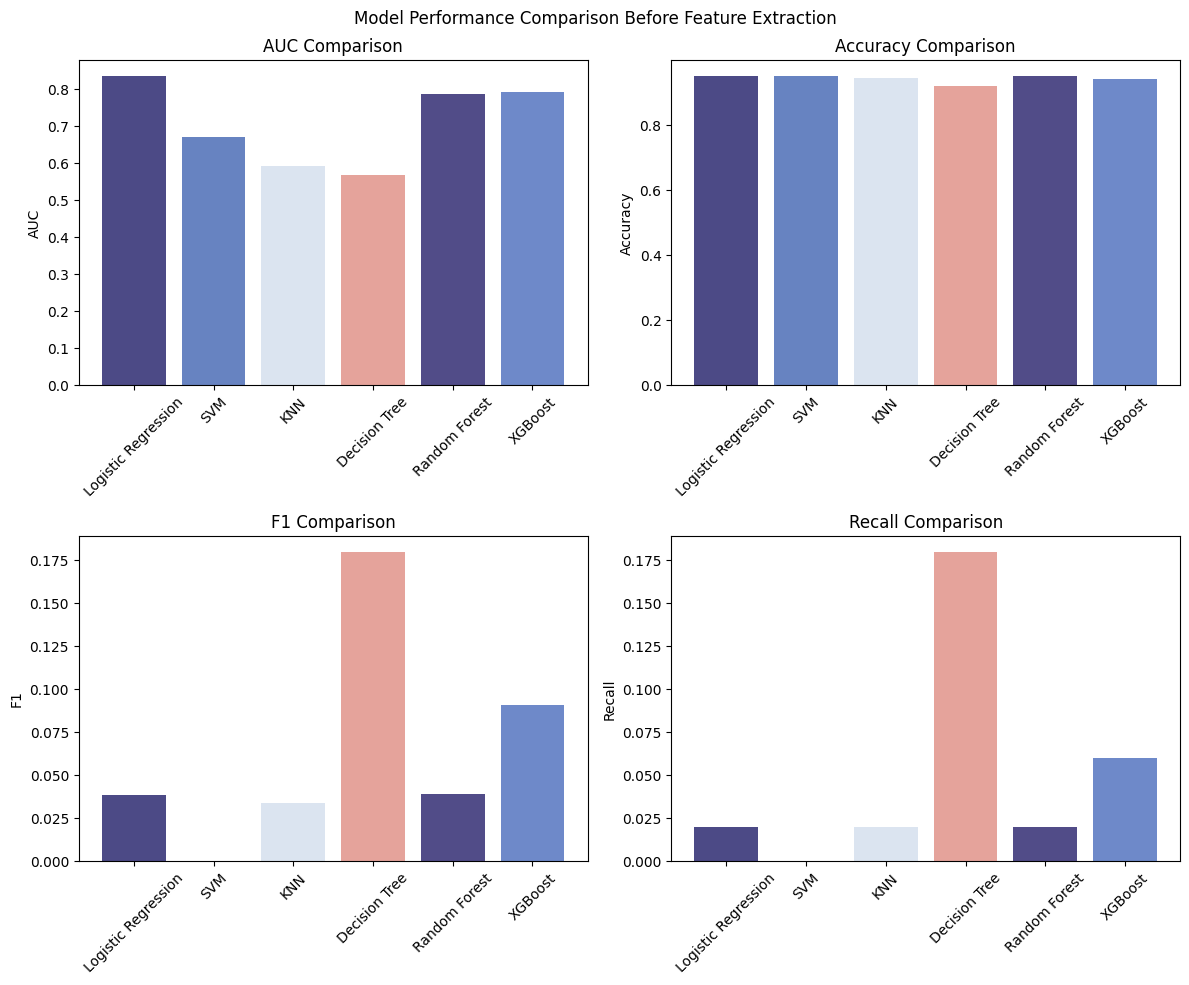

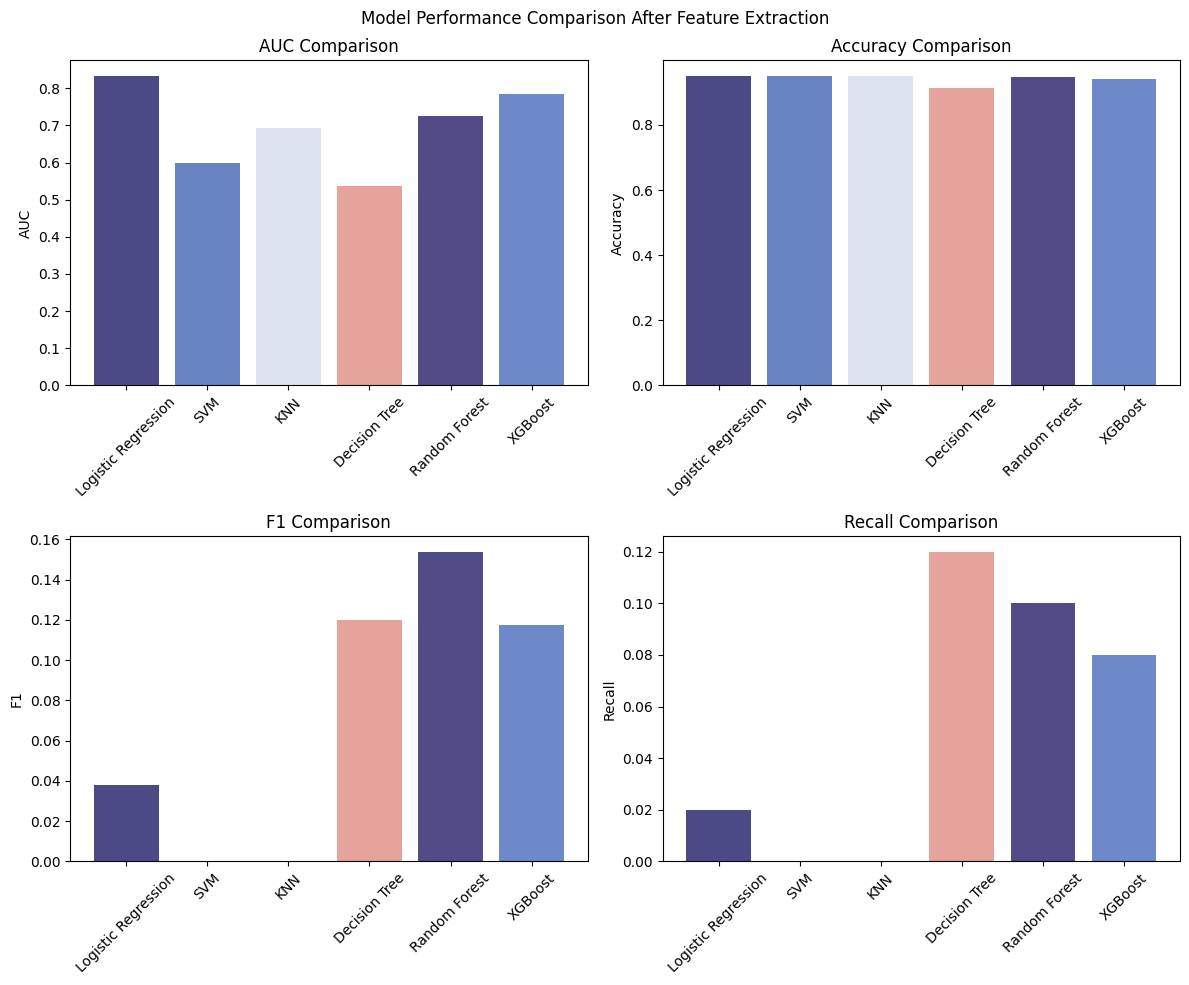

In [18]:
plot_results(results_before, "Model Performance Comparison Before Feature Extraction")
plot_results(results_after, "Model Performance Comparison After Feature Extraction")

In [19]:
import pandas as pd

dnn_before = results_before["DNN"]
dnn_after = results_after["DNN"]

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before[0], 4), round(dnn_before[5], 4)],
    "After Feature Extraction": [round(dnn_after[0], 4), round(dnn_after[5], 4)]
})

print(dnn_table)

     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9511                    0.9481
1       AUC                     0.8138                    0.8261


---- different pipeline -> same results

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, auc

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# optional for reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# The leakage-controlled train/test matrices created above are reused.
# Reproducibility seeds apply to the repeated model comparison below.

In [21]:
# Split, training-only imputation, training-only feature selection, and
# training-only scaling were completed once above.

In [22]:
# -----------------------------
# 4. Evaluation functions
# -----------------------------
def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc


In [23]:
def run_models(X_train, X_test, y_train, y_test):
    results = {}
    trained_models = {}

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    trained_models["Logistic Regression"] = lr
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:, 1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    trained_models["Decision Tree"] = dt
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:, 1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    trained_models["Random Forest"] = rf
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:, 1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    trained_models["SVM"] = svm
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:, 1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    trained_models["KNN"] = knn
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:, 1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    xgb = XGBClassifier(eval_metric='logloss')
    xgb.fit(X_train, y_train)
    trained_models["XGBoost"] = xgb
    y_pred = xgb.predict(X_test)
    y_scores = xgb.predict_proba(X_test)[:, 1]
    results["XGBoost"] = evaluate(y_test, y_pred, y_scores)

    return results, trained_models

results_before, models_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after, models_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

In [24]:
performance = pd.DataFrame({
    "Model": results_after.keys(),
    "AUC": [v[5] for v in results_after.values()]
})

performance = performance.sort_values(
    "AUC",
    ascending=False
)

print(performance)

                 Model       AUC
0  Logistic Regression  0.833807
5              XGBoost  0.785792
2        Random Forest  0.719619
4                  KNN  0.693354
3                  SVM  0.598807
1        Decision Tree  0.519938


In [25]:
test_auc_leader = performance.iloc[0]["Model"]
print(f"Highest observed test AUC (descriptive only): {test_auc_leader}")

Highest observed test AUC (descriptive only): Logistic Regression


In [26]:
# Pre-specified extension model. Logistic regression provides a stable
# probabilistic baseline for the highly imbalanced outcome and was not
# selected by inspecting the held-out test ranking.
selected_model_name = "Logistic Regression"
final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)
final_model.fit(X_train_sel, y_train)
print("Pre-specified XAI model:", selected_model_name)

Pre-specified XAI model: Logistic Regression


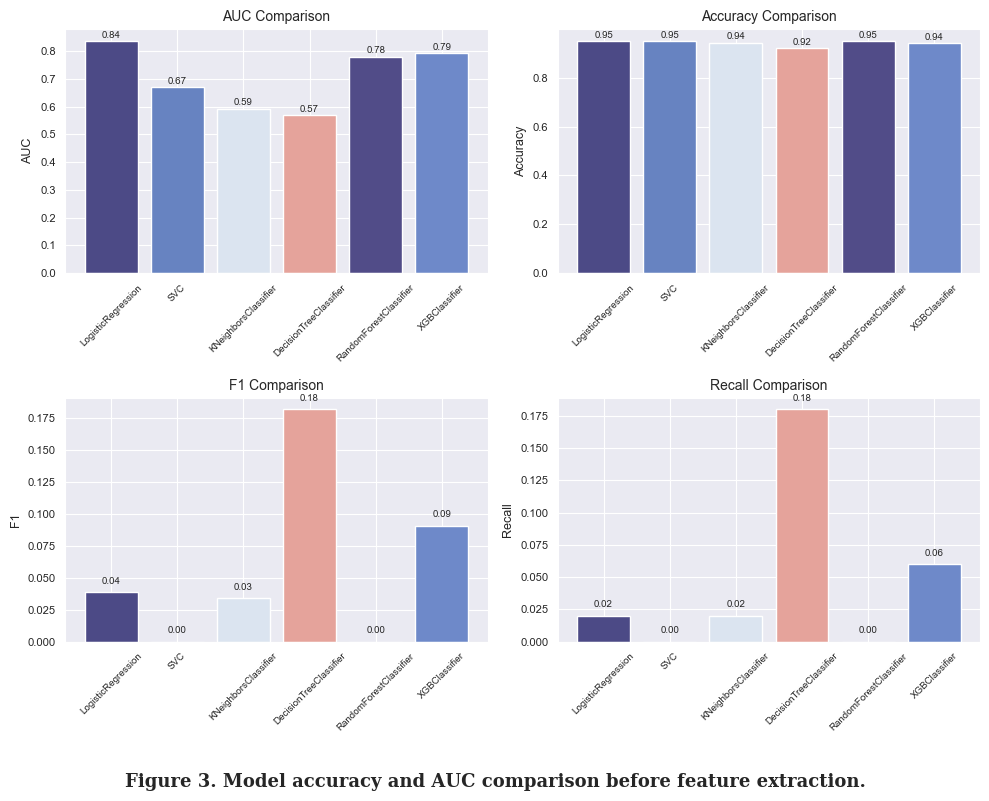

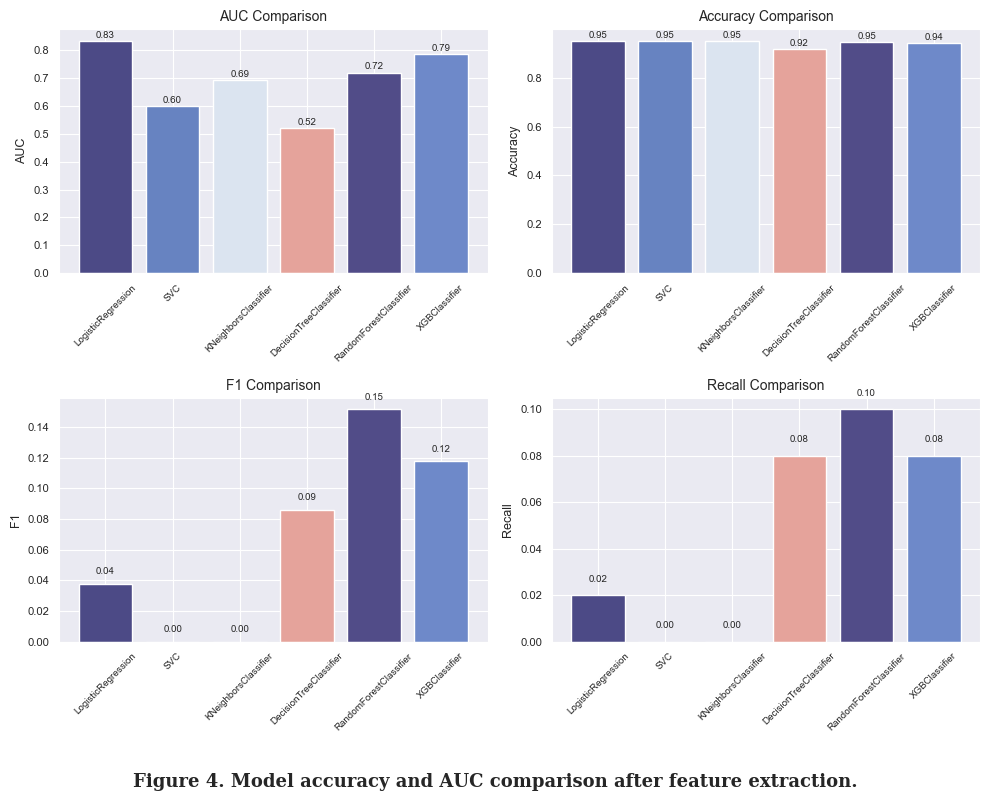

In [27]:
# -----------------------------
# 5. Paper-style plotting
# -----------------------------
def plot_results_paper_style(results, caption_text):
    sns.set_style("darkgrid")

    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    label_map = {
        "Logistic Regression": "LogisticRegression",
        "SVM": "SVC",
        "KNN": "KNeighborsClassifier",
        "Decision Tree": "DecisionTreeClassifier",
        "Random Forest": "RandomForestClassifier",
        "XGBoost": "XGBClassifier"
    }

    display_labels = [label_map[m] for m in plot_models]

    model_colors = [
        "#4c4a86",
        "#6783c1",
        "#dbe4f0",
        "#e5a39b",
        "#514c88",
        "#6e89c9"
    ]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(10, 8))

    metric_info = [
        ("AUC Comparison", aucs, "AUC"),
        ("Accuracy Comparison", acc, "Accuracy"),
        ("F1 Comparison", f1, "F1"),
        ("Recall Comparison", recall, "Recall")
    ]

    for ax, (title, values, ylabel) in zip(axs.flat, metric_info):
        bars = ax.bar(display_labels, values, color=model_colors)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.tick_params(axis='y', labelsize=8)

        for bar, val in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{val:.2f}",
                ha='center',
                va='bottom',
                fontsize=7
            )

    plt.figtext(
        0.5, 0.01,
        caption_text,
        ha='center',
        fontsize=13,
        fontweight='bold',
        family='serif'
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

plot_results_paper_style(
    results_before,
    "Figure 3. Model accuracy and AUC comparison before feature extraction."
)

plot_results_paper_style(
    results_after,
    "Figure 4. Model accuracy and AUC comparison after feature extraction."
)


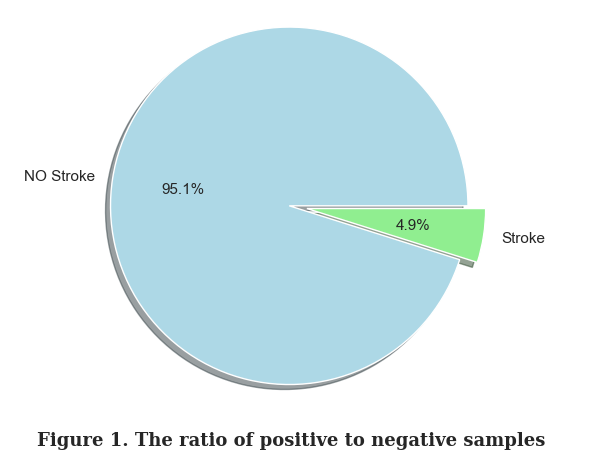

In [28]:
counts = y.value_counts().sort_index()
# Assuming 0 = No Stroke, 1 = Stroke
sizes = [counts[0], counts[1]]
labels = ['NO Stroke', 'Stroke']
colors = ['#add8e6', '#90ee90']  # light blue, light green

fig, ax = plt.subplots(figsize=(6.2, 4.6))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=0,
    explode=(0, 0.1),
    shadow=True,
    textprops={'fontsize': 11}
)

ax.axis('equal')

plt.figtext(
    0.5, 0.02,
    'Figure 1. The ratio of positive to negative samples',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


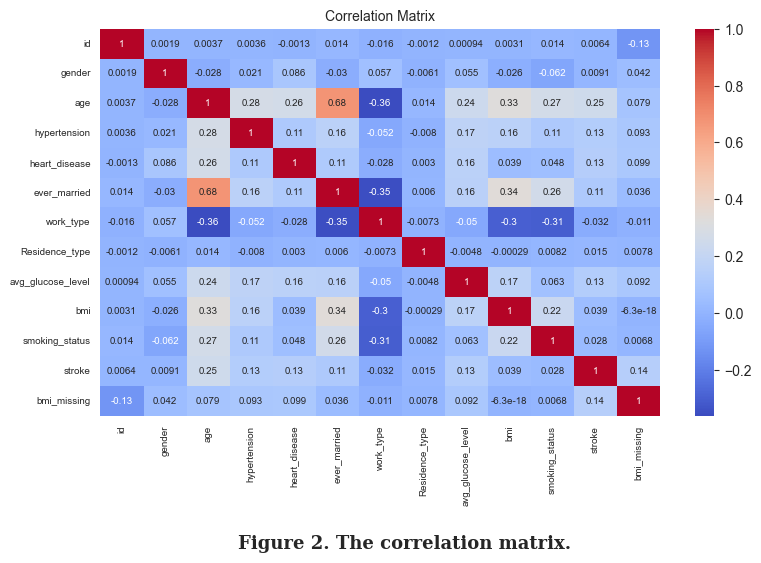

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df_corr = pd.read_csv(file_path)

# Remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other'].copy()

# Create bmi_missing
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# Fill BMI
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# Convert categorical to numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})
df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(8.2, 5.6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2g",
    cmap="coolwarm",
    cbar=True,
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=10)
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)

plt.figtext(
    0.5, 0.01,
    'Figure 2. The correlation matrix.',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


In [30]:
# -----------------------------
# 4. DNN evaluation function
# -----------------------------
from sklearn.metrics import accuracy_score, roc_curve, auc

def run_dnn(X_train, X_test, y_train, y_test):
    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)

    return acc, roc_auc

# -----------------------------
# 5. Compute DNN results
# -----------------------------
dnn_before_acc, dnn_before_auc = run_dnn(X_train_full, X_test_full, y_train, y_test)
dnn_after_acc, dnn_after_auc = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before_acc, 4), round(dnn_before_auc, 4)],
    "After Feature Extraction": [round(dnn_after_acc, 4), round(dnn_after_auc, 4)]
})

print(dnn_table)


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9511                    0.9481
1       AUC                     0.8080                    0.8323


FOR PIPELINE

In [31]:
from sklearn.base import clone

feature_names = list(X_train_sel.columns)

best_model = final_model


def train_model_fn(seed):
    model = clone(best_model)

    params = model.get_params(deep=False)

    if "random_state" in params:
        model.set_params(random_state=seed)

    model.fit(X_train_sel, y_train)

    return model

In [32]:
config = {
    "dataset_name": "stroke",

    "model": best_model,

    "X_train": X_train_sel,
    "X_test": X_test_sel,

    "y_train": y_train,
    "y_test": y_test,

    "feature_names": feature_names,

    "train_model_fn": train_model_fn,

    "scoring": "roc_auc",

    "output_dir": "../../results/stroke"
}

experiment = run_pipeline(config)

ExactExplainer explainer: 1023it [00:30, 33.94it/s]                          


Results exported to: ../../results/stroke


# Validation

In [33]:
print("Dataset:", config["dataset_name"])
print("Model:", type(config["model"]).__name__)

print("X_train shape:", config["X_train"].shape)
print("X_test shape:", config["X_test"].shape)

print("y_train length:", len(config["y_train"]))
print("y_test length:", len(config["y_test"]))

print("Feature names:", len(config["feature_names"]))

Dataset: stroke
Model: LogisticRegression
X_train shape: (4087, 7)
X_test shape: (1022, 7)
y_train length: 4087
y_test length: 1022
Feature names: 7


#### Consistency

In [34]:
assert config["X_train"].shape[1] == len(config["feature_names"])
assert config["X_test"].shape[1] == len(config["feature_names"])

assert len(config["X_train"]) == len(config["y_train"])
assert len(config["X_test"]) == len(config["y_test"])

print("Basic shape validation: OK")

Basic shape validation: OK


#### Fitted model predicts on the configured data

In [35]:
model = config["model"]
X_test = config["X_test"]

if hasattr(model, "predict_proba"):
    probs = model.predict_proba(X_test)[:, 1]
    print("Probability range:", probs.min(), probs.max())

preds = model.predict(X_test)

print("Predictions:", np.unique(preds, return_counts=True))
print("Prediction test: OK")

Probability range: 0.0088262240727006 0.9864089793069091
Predictions: (array([0, 1]), array([741, 281]))
Prediction test: OK


#### Results from Framework

In [36]:
global_results = experiment.state.results["global"]
local_results = experiment.state.results["local"]
stability_results = experiment.state.results["stability"]

print(global_results.keys())
print(local_results.keys())

if stability_results is not None:
    print(stability_results.keys())
else:
    print("Stability: not available")

dict_keys(['native_importance', 'permutation_importance', 'shap_importance', 'shap_values', 'shap_raw_values', 'explainer', 'rank_compare', 'rank_agreement'])
dict_keys(['cases', 'lime'])
dict_keys(['raw', 'summary', 'rank_stability'])


#### Global XAI

In [37]:
native_df = global_results["native_importance"]
perm_df = global_results["permutation_importance"]
shap_df = global_results["shap_importance"]

print("Native:")
display(native_df.head())

print("Permutation:")
display(perm_df.head())

print("SHAP:")
display(shap_df.head())

Native:


,Feature,Importance,RawValue,Method
0,age,1.674441,1.674441,coefficients
4,bmi_missing,0.331027,0.331027,coefficients
3,avg_glucose_level,0.212911,0.212911,coefficients
1,hypertension,0.205457,0.205457,coefficients
2,heart_disease,0.059397,0.059397,coefficients


Permutation:


,Feature,Importance,Std
0,age,0.291633,0.028744
3,avg_glucose_level,0.004798,0.003867
4,bmi_missing,0.003608,0.003121
2,heart_disease,0.001931,0.000932
5,ever_married_No,-0.000357,0.000490


SHAP:


,Feature,MeanAbsSHAP,MeanSHAP
0,age,0.224165,-0.019177
1,avg_glucose_level,0.028314,-0.004800
2,hypertension,0.021344,0.001532
3,bmi_missing,0.016160,0.002403
4,heart_disease,0.003113,0.000240


#### Feature coverage

In [38]:
if native_df is not None:
    print("Native features:", len(native_df))

print("Permutation features:", len(perm_df))
print("SHAP features:", len(shap_df))
print("Expected features:", len(config["feature_names"]))

Native features: 7
Permutation features: 7
SHAP features: 7
Expected features: 7


#### Broken values

In [39]:
print("Permutation NaNs:", perm_df.isna().sum().sum())
print("SHAP NaNs:", shap_df.isna().sum().sum())

if native_df is not None:
    print("Native NaNs:", native_df.isna().sum().sum())

Permutation NaNs: 0
SHAP NaNs: 0
Native NaNs: 0


#### Rank agreement

In [40]:
print(global_results["rank_agreement"])

display(global_results["rank_compare"].head())

{'Native_vs_SHAP': np.float64(0.8928571428571429), 'Native_vs_Permutation': np.float64(0.7387687194103585), 'SHAP_vs_Permutation': np.float64(0.6306562238868914)}


,Feature,Importance_x,RawValue,Method,NativeRank,MeanAbsSHAP,MeanSHAP,SHAPRank,Importance_y,Std,PermutationRank
0,age,1.674441,1.674441,coefficients,1.0,0.224165,-0.019177,1.0,0.291633,0.028744,1.0
1,bmi_missing,0.331027,0.331027,coefficients,2.0,0.016160,0.002403,4.0,0.003608,0.003121,3.0
2,avg_glucose_level,0.212911,0.212911,coefficients,3.0,0.028314,-0.004800,2.0,0.004798,0.003867,2.0
3,hypertension,0.205457,0.205457,coefficients,4.0,0.021344,0.001532,3.0,-0.000742,0.003242,7.0
4,heart_disease,0.059397,0.059397,coefficients,5.0,0.003113,0.000240,5.0,0.001931,0.000932,4.0


#### Representative cases

In [41]:
cases = local_results["cases"]

display(
    cases[
        ["CaseType", "y_true", "y_pred", "y_prob"]
    ]
)

,CaseType,y_true,y_pred,y_prob
207,TP,1,1,0.974578
662,TN,0,0,0.008826
96,FP,0,1,0.986409
553,FN,1,0,0.024162
361,Borderline,0,1,0.500372


#### LIME

In [42]:
lime_df = local_results["lime"]

print("LIME rows:", len(lime_df))
display(lime_df.head())

LIME rows: 35


,CaseIndex,Prediction,Probability,Rule,Weight
0,207,1,0.974578,age > 0.78,0.516819
1,207,1,0.974578,bmi_missing > -0.20,0.243195
2,207,1,0.974578,hypertension <= -0.32,-0.090770
3,207,1,0.974578,avg_glucose_level > 0.18,0.063422
4,207,1,0.974578,heart_disease > -0.25,0.040900


#### Stability

In [43]:
if stability_results is not None:
    display(stability_results["raw"].head())
    print(stability_results["summary"])

,Feature,Importance,ImportanceStd,Seed,Rank
0,age,0.288523,0.039467,1,1.0
1,hypertension,-0.000790,0.002368,1,7.0
2,heart_disease,0.002794,0.000741,1,3.0
3,avg_glucose_level,0.003955,0.003595,1,2.0
4,bmi_missing,0.000181,0.004198,1,4.0


             Feature  MeanImportance  StdImportance  MeanRank   StdRank
0                age        0.286439       0.009285       1.0  0.000000
1  avg_glucose_level        0.005657       0.001279       2.0  0.000000
5      heart_disease        0.002392       0.000293       3.4  0.547723
2        bmi_missing        0.001752       0.002386       4.2  1.643168
3    ever_married_No       -0.000539       0.000165       5.5  0.000000
4   ever_married_Yes       -0.000539       0.000165       5.5  0.000000
6       hypertension       -0.001026       0.000381       6.4  1.341641


#### Exported folder

In [44]:
from pathlib import Path

out_dir = Path(config["output_dir"]).resolve()

print("Output directory:", out_dir)

for path in sorted(out_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(out_dir))

Output directory: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\stroke
bundle\metadata.json
bundle\model.pkl
bundle\X_test.csv
bundle\X_train.csv
bundle\y_test.csv
bundle\y_train.csv
lime_explanations.csv
native_importance.csv
permutation_importance.csv
rank_agreement\Native_vs_Permutation.json
rank_agreement\Native_vs_SHAP.json
rank_agreement\SHAP_vs_Permutation.json
rank_compare.csv
representative_cases.csv
shap_importance.csv
stability.csv
stability_rank.csv
stability_summary.csv


In [45]:
print(
    experiment.state.results["local"]["cases"].columns.tolist()
)

display(
    experiment.state.results["local"]["cases"]
)

['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes', 'y_true', 'y_pred', 'y_prob', 'distance', 'CaseType', 'CaseIndex']


,age,hypertension,heart_disease,avg_glucose_level,bmi_missing,ever_married_No,ever_married_Yes,y_true,y_pred,y_prob,distance,CaseType,CaseIndex
207,1.533528,-0.323411,4.076319,2.550736,4.906488,-0.717905,0.717905,1,1,0.974578,0.474578,TP,207
662,-1.908375,-0.323411,-0.245319,-1.018439,-0.203812,1.392942,-1.392942,0,0,0.008826,0.491174,TN,662
96,1.533528,3.092042,4.076319,2.252783,4.906488,-0.717905,0.717905,0,1,0.986409,0.486409,FP,96
553,-1.290598,-0.323411,-0.245319,-1.073732,-0.203812,1.392942,-1.392942,1,0,0.024162,0.475838,FN,553
361,0.606862,-0.323411,-0.245319,1.870211,-0.203812,-0.717905,0.717905,0,1,0.500372,0.000372,Borderline,361


In [46]:
assert "CaseIndex" in experiment.state.results["local"]["cases"].columns
print("Stroke CaseIndex exists in memory.")

Stroke CaseIndex exists in memory.


In [47]:
stroke_cases = pd.read_csv(
    Path("../../results/stroke/representative_cases.csv")
)

print(stroke_cases.columns.tolist())
display(stroke_cases)

['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes', 'y_true', 'y_pred', 'y_prob', 'distance', 'CaseType', 'CaseIndex']


,age,hypertension,heart_disease,avg_glucose_level,bmi_missing,ever_married_No,ever_married_Yes,y_true,y_pred,y_prob,distance,CaseType,CaseIndex
0,1.533528,-0.323411,4.076319,2.550736,4.906488,-0.717905,0.717905,1,1,0.974578,0.474578,TP,207
1,-1.908375,-0.323411,-0.245319,-1.018439,-0.203812,1.392942,-1.392942,0,0,0.008826,0.491174,TN,662
2,1.533528,3.092042,4.076319,2.252783,4.906488,-0.717905,0.717905,0,1,0.986409,0.486409,FP,96
3,-1.290598,-0.323411,-0.245319,-1.073732,-0.203812,1.392942,-1.392942,1,0,0.024162,0.475838,FN,553
4,0.606862,-0.323411,-0.245319,1.870211,-0.203812,-0.717905,0.717905,0,1,0.500372,0.000372,Borderline,361
